In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
np.random.seed(42)

df = pd.read_csv('rsvp_wedding_data.csv')

print("=== 5 Baris Pertama Data ===")
df.head()

=== 5 Baris Pertama Data ===


,jarak_domisili_km,status_kedekatan,usia,bawa_pasangan,waktu_respons_hari,hadir
0,33,Keluarga,31,1,3,1
1,17,Keluarga,27,1,6,1
2,38,Teman Kerja,38,0,1,1
3,92,Teman Kerja,48,1,1,1
4,15,Keluarga,18,1,1,1


In [7]:
X = df.drop('hadir', axis=1)
y = df['hadir']

X_encoded = pd.get_dummies(X, columns=['status_kedekatan'], drop_first=True, dtype=int)

print("\n=== Data Setelah One-Hot Encoding ===")
print(X_encoded.head())

X_train, X_test, y_train, y_test = train_test_split(
   X_encoded, y, test_size=0.2, random_state=42
)

kolom_numerik = ['jarak_domisili_km', 'usia', 'waktu_respons_hari']
scaler = StandardScaler()
X_train[kolom_numerik] = scaler.fit_transform(X_train[kolom_numerik])
X_test[kolom_numerik] = scaler.transform(X_test[kolom_numerik])


model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\n=== Hasil Evaluasi Model ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Hadir', 'Hadir']))



=== Data Setelah One-Hot Encoding ===
   jarak_domisili_km  usia  bawa_pasangan  waktu_respons_hari  \
0                 33    31              1                   3   
1                 17    27              1                   6   
2                 38    38              0                   1   
3                 92    48              1                   1   
4                 15    18              1                   1   

   status_kedekatan_Lainnya  status_kedekatan_Teman Kerja  \
0                         0                             0   
1                         0                             0   
2                         0                             1   
3                         0                             1   
4                         0                             0   

   status_kedekatan_Teman Sekolah  
0                               0  
1                               0  
2                               0  
3                               0  
4                      

Feature Engineering

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv('rsvp_wedding_data.csv')

df = df.drop('usia', axis=1)

df['kategori_jarak'] = pd.cut(
    df['jarak_domisili_km'], 
    bins=[0, 20, 100, 1000], 
    labels=['Dekat', 'Menengah', 'Jauh']
)

df['kategori_respons'] = pd.cut(
    df['waktu_respons_hari'], 
    bins=[0, 3, 14, 30], 
    labels=['Cepat', 'Sedang', 'Lambat']
)

df = df.drop(['jarak_domisili_km', 'waktu_respons_hari'], axis=1)

X = df.drop('hadir', axis=1)
y = df['hadir']

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\n=== Hasil Evaluasi Model ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Hadir', 'Hadir']))


=== Hasil Evaluasi Model ===
Akurasi: 0.74

Classification Report:
              precision    recall  f1-score   support

 Tidak Hadir       0.50      0.65      0.56        51
       Hadir       0.87      0.78      0.82       149

    accuracy                           0.74       200
   macro avg       0.68      0.71      0.69       200
weighted avg       0.77      0.74      0.75       200



Feature Engineering + Hyperparameter tuning

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

base_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=2000)

# PERBAIKAN: Gunakan parameter 'penalty' alih-alih 'l1_ratio'
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],         # Menguji L1 dan L2 secara langsung
    'solver': ['liblinear', 'saga']  # Kedua solver ini mendukung L1 dan L2
}

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("\n=== Laporan Optimasi Model ===")
print(f"Parameter Terbaik : {grid_search.best_params_}")

print("\n=== Hasil Evaluasi Model ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Hadir', 'Hadir']))


=== Laporan Optimasi Model ===
Parameter Terbaik : {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}

=== Hasil Evaluasi Model ===
Akurasi: 0.76

Classification Report:
              precision    recall  f1-score   support

 Tidak Hadir       0.52      0.65      0.58        51
       Hadir       0.87      0.80      0.83       149

    accuracy                           0.76       200
   macro avg       0.70      0.72      0.71       200
weighted avg       0.78      0.76      0.77       200



Undersampling

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils import resample

# --- Proses Persiapan Data (Sama seperti kode Anda) ---
df = pd.read_csv('rsvp_wedding_data.csv')
df = df.drop('usia', axis=1)

df['kategori_jarak'] = pd.cut(
    df['jarak_domisili_km'], 
    bins=[0, 20, 100, 1000], 
    labels=['Dekat', 'Menengah', 'Jauh']
)

df['kategori_respons'] = pd.cut(
    df['waktu_respons_hari'], 
    bins=[0, 3, 14, 30], 
    labels=['Cepat', 'Sedang', 'Lambat']
)

df = df.drop(['jarak_domisili_km', 'waktu_respons_hari'], axis=1)

df_hadir = df[df['hadir'] == 1]
df_tidak_hadir = df[df['hadir'] == 0]

print(f"Jumlah sampel sebelum balancing:")
print(f"  Hadir       : {len(df_hadir)}")
print(f"  Tidak Hadir : {len(df_tidak_hadir)}")

if len(df_hadir) > len(df_tidak_hadir):
    df_hadir_downsampled = resample(
        df_hadir,
        replace=False,
        n_samples=len(df_tidak_hadir),
        random_state=42
    )
    df_balanced = pd.concat([df_hadir_downsampled, df_tidak_hadir])
    print(f"\nHadir diturunkan dari {len(df_hadir)} menjadi {len(df_hadir_downsampled)}")
else:
    df_tidak_hadir_downsampled = resample(
        df_tidak_hadir,
        replace=False,
        n_samples=len(df_hadir),
        random_state=42
    )
    df_balanced = pd.concat([df_hadir, df_tidak_hadir_downsampled])
    print(f"\nTidak Hadir diturunkan dari {len(df_tidak_hadir)} menjadi {len(df_tidak_hadir_downsampled)}")

print(f"Total sampel setelah balancing: {len(df_balanced)}")
print(f"  Hadir       : {len(df_balanced[df_balanced['hadir'] == 1])}")
print(f"  Tidak Hadir : {len(df_balanced[df_balanced['hadir'] == 0])}")

# --- Proses Modeling ---
X = df_balanced.drop('hadir', axis=1)
y = df_balanced['hadir']

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Hapus class_weight='balanced' karena data sudah di-balance secara manual
base_model = LogisticRegression(random_state=42, max_iter=2000)

# PERBAIKAN: Gunakan 'penalty' alih-alih 'l1_ratio'
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],  # Untuk menguji penalti L1 dan L2
    'solver': ['liblinear', 'saga']
}

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("\n=== Laporan Optimasi Model ===")
print(f"Parameter Terbaik : {grid_search.best_params_}")

print("\n=== Hasil Evaluasi Model ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Tidak Hadir', 'Hadir']))

Jumlah sampel sebelum balancing:
  Hadir       : 748
  Tidak Hadir : 252

Hadir diturunkan dari 748 menjadi 252
Total sampel setelah balancing: 504
  Hadir       : 252
  Tidak Hadir : 252

=== Laporan Optimasi Model ===
Parameter Terbaik : {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}

=== Hasil Evaluasi Model ===
Akurasi: 0.78

Classification Report:
              precision    recall  f1-score   support

 Tidak Hadir       0.83      0.74      0.78        54
       Hadir       0.74      0.83      0.78        47

    accuracy                           0.78       101
   macro avg       0.78      0.79      0.78       101
weighted avg       0.79      0.78      0.78       101



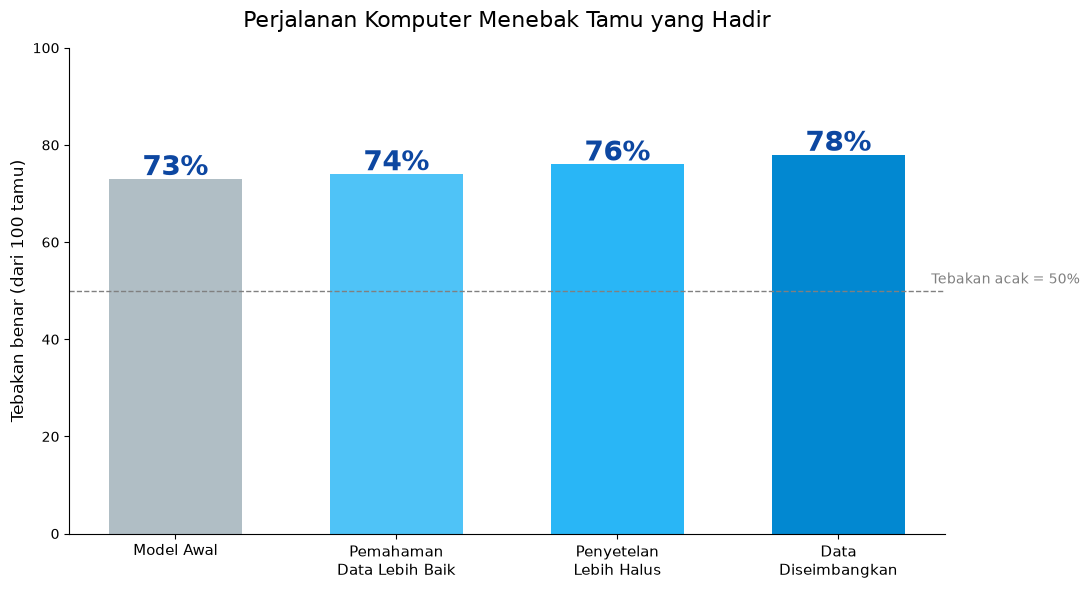

In [11]:
import matplotlib.pyplot as plt

# Akurasi dari RSVP_Prediction.ipynb: Out 1, Out 3, Out 5, Out 7
tahapan = [
    "Model Awal",
    "Pemahaman\nData Lebih Baik",
    "Penyetelan\nLebih Halus",
    "Data\nDiseimbangkan",
]
akurasi = [0.73, 0.74, 0.76, 0.78]
colors = ["#B0BEC5", "#4FC3F7", "#29B6F6", "#0288D1"]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(tahapan, [a * 100 for a in akurasi], color=colors, width=0.6)

for bar, acc in zip(bars, akurasi):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{acc * 100:.0f}%",
        ha="center",
        fontsize=20,
        fontweight="bold",
        color="#0D47A1",
    )

ax.set_ylim(0, 100)
ax.set_ylabel("Tebakan benar (dari 100 tamu)", fontsize=12)
ax.set_title("Perjalanan Komputer Menebak Tamu yang Hadir", fontsize=16, pad=15)
ax.axhline(50, color="gray", linestyle="--", linewidth=1)
ax.text(3.42, 51.5, "Tebakan acak = 50%", fontsize=10, color="gray")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", labelsize=11)

plt.tight_layout()
plt.savefig("slide_rsvp_akurasi.png", dpi=300, bbox_inches="tight")
plt.show()